# The Delivery Gap: Olist delivery promises vs reality

## 1. The question

When someone buys on Olist, the site shows a promised delivery date. In this notebook I want to find out:

- How often is that promise missed, and by how much?
- What does a late order cost in review scores and in repeat buying?
- Where does lateness come from (customer state, distance, the seller shipping late, the month)?
- Is the promise too padded? Most orders arrive well before the promised date. A long promise might put people off at checkout, so could Olist promise less without many more late orders?

The data is one row per delivered order from the `order_delivery` view I built in SQL (`sql/03_views.sql`).
Everything here is association, not cause, and it covers one marketplace in 2016-2018.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

# my colour palette, used in every chart
NAVY, TERRA, SAND, SAGE, GREY = "#1F3A5F", "#C8553D", "#E9D8A6", "#8AA399", "#9AA5B1"

sns.set_theme(style="white")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 11,
    "axes.labelcolor": "#333333",
    "font.size": 10,
})

IMG = Path("../images")
IMG.mkdir(exist_ok=True)

def save(fig, name):
    # save every key chart to images/ at the same size and dpi
    fig.savefig(IMG / name, dpi=150, bbox_inches="tight", facecolor="white")

## 2. Load the data and a quick check

I read the view straight from PostgreSQL. The password is in my pgpass file, so it is not in the code.

In [2]:
from sqlalchemy import create_engine

try:
    engine = create_engine("postgresql+psycopg2://analyst@localhost:5432/olist")
    df = pd.read_sql("SELECT * FROM order_delivery", engine)
    source = "PostgreSQL view order_delivery"
except Exception as e:
    # if the database is not running (for example on another computer),
    # use the CSV export of the same view so the notebook still runs
    print("Could not connect to the database:", type(e).__name__)
    df = pd.read_csv("../data/export/order_delivery.csv")
    source = "data/export/order_delivery.csv"

# make the types the same whichever source was used
for col in ["is_late", "seller_shipped_late", "same_state"]:
    df[col] = df[col].map({True: True, False: False, "t": True, "f": False, "true": True, "false": False})
for col in ["purchased_at", "delivered_at", "promised_date", "purchase_month"]:
    df[col] = pd.to_datetime(df[col])

print("Source:", source)
print("Rows:", f"{len(df):,}", "| Columns:", df.shape[1])
print("Orders from", df.purchased_at.min().date(), "to", df.purchased_at.max().date())

Source: PostgreSQL view order_delivery
Rows: 96,470 | Columns: 23
Orders from 2016-09-15 to 2018-08-29


In [3]:
# which columns have missing values?
nulls = df.isna().sum()
nulls[nulls > 0].to_frame("missing")

,missing
seller_shipped_late,1
distance_km,478
review_score,646


Only three columns have gaps: `distance_km` (a zip code with no location), `review_score` (no review for the order)
and `seller_shipped_late` (one order with no hand-over time). They are small, so I just leave those rows out when a test needs that column.

## 3. How late, and how early?

`days_early` is the promised date minus the delivered date, so a negative number means the order was late.

In [4]:
late_rate = df.is_late.mean()
print(f"Late orders: {df.is_late.sum():,} of {len(df):,} = {late_rate:.2%}")
print("Median days early:", df.days_early.median())
pct = df.days_early.quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
pct.index = [f"p{int(q*100)}" for q in pct.index]
print(pct.to_string())
print()
print(f"Average days promised: {df.promised_days.mean():.1f}  |  average days to deliver: {df.delivery_days.mean():.1f}")
print(f"Median days promised: {df.promised_days.median():.0f}  |  median days to deliver: {df.delivery_days.median():.0f}")

Late orders: 6,534 of 96,470 = 6.77%
Median days early: 12.0
p5     -3.0
p10     2.0
p25     7.0
p50    12.0
p75    17.0
p90    22.0
p95    26.0

Average days promised: 24.4  |  average days to deliver: 12.5
Median days promised: 24  |  median days to deliver: 10


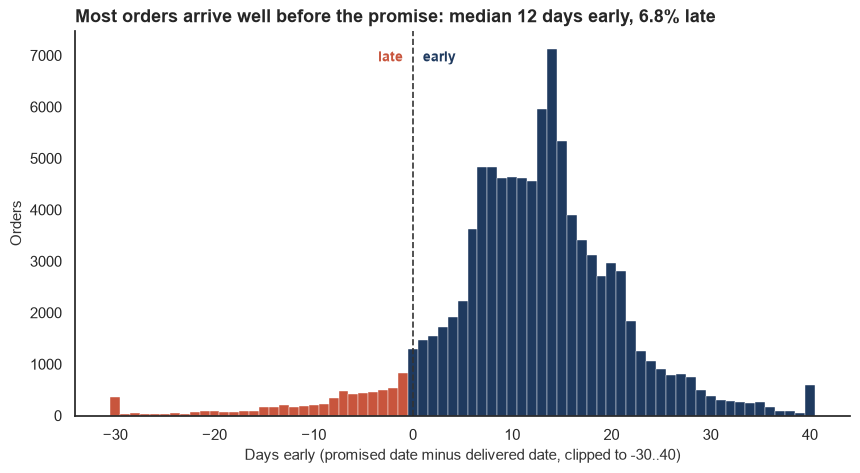

In [5]:
clipped = df.days_early.clip(-30, 40)
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.arange(-30.5, 41.5, 1)
n, b, patches = ax.hist(clipped, bins=bins, color=NAVY, edgecolor="white", linewidth=0.3)
for p, left in zip(patches, b[:-1]):
    if left < -0.5:          # bars left of zero are late orders
        p.set_facecolor(TERRA)
ax.axvline(0, color="#333333", linewidth=1.2, linestyle="--")
ax.text(-1, ax.get_ylim()[1] * 0.92, "late", ha="right", color=TERRA, fontweight="bold")
ax.text(1, ax.get_ylim()[1] * 0.92, "early", ha="left", color=NAVY, fontweight="bold")
med = df.days_early.median()
ax.set_title(f"Most orders arrive well before the promise: median {med:.0f} days early, {late_rate:.1%} late")
ax.set_xlabel("Days early (promised date minus delivered date, clipped to -30..40)")
ax.set_ylabel("Orders")
save(fig, "chart_days_early.png")
plt.show()

Most of the bars are on the right side of the line. The typical order arrives almost two weeks before the date the customer was shown.
Only a small slice is late, but some of those are very late.

## 4. Reviews by delivery group

I put orders into four groups by how they arrived compared with the promise, and look at the review score for each group.

In [6]:
rev = df.dropna(subset=["review_score"]).copy()
rev["low_review"] = rev.review_score <= 2

by_group = (df.groupby("delivery_group")
              .agg(orders=("order_id", "size"))
              .join(rev.groupby("delivery_group")
                       .agg(reviews=("review_score", "size"),
                            avg_review=("review_score", "mean"),
                            low_share=("low_review", "mean"))))
by_group.style.format({"orders": "{:,}", "reviews": "{:,}", "avg_review": "{:.2f}", "low_share": "{:.1%}"})

,orders,reviews,avg_review,low_share
delivery_group,,,,
1. Late,"6,534","6,381",2.27,62.4%
2. 0-6 days early,"13,796","13,699",4.17,10.8%
3. 7-13 days early,"34,075","33,883",4.30,8.9%
4. 14+ days early,"42,065","41,861",4.32,9.1%


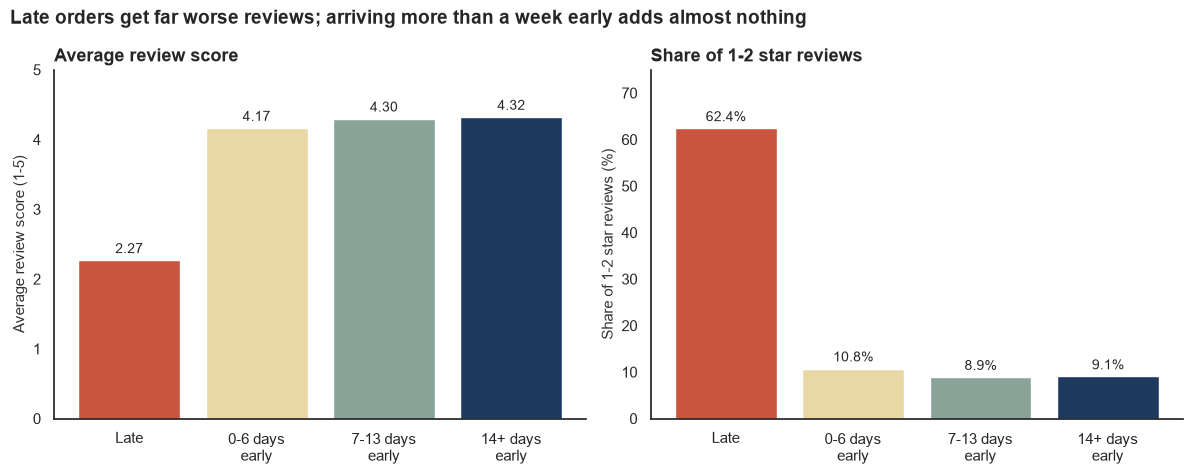

In [7]:
labels = ["Late", "0-6 days\nearly", "7-13 days\nearly", "14+ days\nearly"]
colors = [TERRA, SAND, SAGE, NAVY]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
bars = ax.bar(labels, by_group.avg_review, color=colors)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_ylim(0, 5)
ax.set_ylabel("Average review score (1-5)")
ax.set_title("Average review score")

ax = axes[1]
bars = ax.bar(labels, by_group.low_share * 100, color=colors)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in by_group.low_share], padding=3)
ax.set_ylim(0, 75)
ax.set_ylabel("Share of 1-2 star reviews (%)")
ax.set_title("Share of 1-2 star reviews")

fig.suptitle("Late orders get far worse reviews; arriving more than a week early adds almost nothing",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save(fig, "chart_reviews_by_group.png")
plt.show()

The big drop is between late and on time. Among the on-time groups, going from "0-6 days early" to "7-13 days early" helps a little,
but going from "7-13" to "14+" does not help at all. So a lot of the padding in the promise is not buying better reviews.

## 5. Statistics: is the link between lateness and bad reviews real?

**Why these tests:**

- **Chi-square test of independence.** Both things are yes/no (late or not, 1-2 stars or not), so a 2x2 table and a chi-square test is the standard check.
  With almost 96,000 reviews almost any difference will be "significant", so I also report **Cramer's V** to show how strong the link is (0 = none, 1 = perfect).
- **Mann-Whitney U test.** Review scores are on a 1-5 scale and are very skewed (lots of 5s), so they are not normal and a t-test is not a good fit.
  Mann-Whitney compares the two groups by ranks, so it does not need normal data. I also report the rank-biserial correlation as the effect size.

In [8]:
# chi-square: late vs low review (1-2 stars)
table = pd.crosstab(rev.is_late, rev.low_review)
table.index = ["On time", "Late"]
table.columns = ["3-5 stars", "1-2 stars"]
print(table, "\n")

chi2, p_chi, dof, expected = stats.chi2_contingency(table)
n_obs = table.values.sum()
cramers_v = np.sqrt(chi2 / (n_obs * (min(table.shape) - 1)))
print(f"Chi-square = {chi2:,.1f}, dof = {dof}, p-value = {p_chi:.3g}")
print(f"Cramer's V = {cramers_v:.3f}")

low_late = rev.loc[rev.is_late, "low_review"].mean()
low_ontime = rev.loc[~rev.is_late, "low_review"].mean()
print(f"1-2 star share: late {low_late:.1%} vs on time {low_ontime:.1%} ({low_late/low_ontime:.1f}x)")

         3-5 stars  1-2 stars
On time      81154       8289
Late          2398       3983 

Chi-square = 15,064.1, dof = 1, p-value = 0
Cramer's V = 0.396
1-2 star share: late 62.4% vs on time 9.3% (6.7x)


In [9]:
# Mann-Whitney U: review scores of late vs on-time orders
late_scores = rev.loc[rev.is_late, "review_score"]
ontime_scores = rev.loc[~rev.is_late, "review_score"]
u_stat, p_mw = stats.mannwhitneyu(late_scores, ontime_scores, alternative="two-sided")

# rank-biserial correlation as the effect size
rank_biserial = 2 * u_stat / (len(late_scores) * len(ontime_scores)) - 1
print(f"Late: n = {len(late_scores):,}, mean = {late_scores.mean():.2f}, median = {late_scores.median():.0f}")
print(f"On time: n = {len(ontime_scores):,}, mean = {ontime_scores.mean():.2f}, median = {ontime_scores.median():.0f}")
print(f"Mann-Whitney U = {u_stat:,.0f}, p-value = {p_mw:.3g}")
print(f"Rank-biserial correlation = {rank_biserial:.3f}  (negative = late orders score lower)")

Late: n = 6,381, mean = 2.27, median = 1
On time: n = 89,443, mean = 4.29, median = 5
Mann-Whitney U = 103,305,546, p-value = 0
Rank-biserial correlation = -0.638  (negative = late orders score lower)


Both tests give p-values that are basically zero (too small to print), so the link is not chance. More useful is the size:
Cramer's V is about 0.4 and the rank-biserial correlation is about -0.64, which is a strong link for one yes/no variable.
This still does not prove that lateness *causes* the bad review (for example, an order that is late may also have other problems),
and only people who chose to leave a review are counted.

## 6. Where does lateness come from?

I look at the late rate by customer state, by distance between seller and customer, and by whether the seller handed the parcel to the carrier late.

In [10]:
overall = df.is_late.mean()

# late rate by customer state, only states with at least 500 orders so small states do not jump around
state = (df.groupby("customer_state")
           .agg(orders=("order_id", "size"), late_rate=("is_late", "mean"))
           .query("orders >= 500")
           .sort_values("late_rate", ascending=False))
print(f"States with 500+ orders: {len(state)}")
state.head(10).style.format({"orders": "{:,}", "late_rate": "{:.1%}"})

States with 500+ orders: 17


,orders,late_rate
customer_state,,
MA,717,17.4%
CE,"1,279",13.8%
BA,"3,256",12.2%
RJ,"12,350",12.1%
PA,946,11.2%
ES,"1,995",10.7%
PB,517,10.4%
MS,701,9.7%
PE,"1,593",9.6%


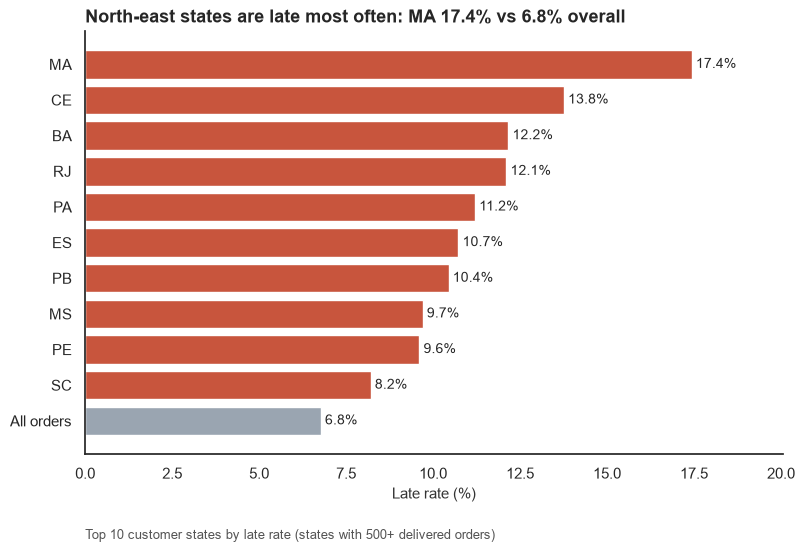

In [11]:
top10 = state.head(10).copy()
plot = pd.concat([top10.late_rate, pd.Series({"All orders": overall})])[::-1]

fig, ax = plt.subplots(figsize=(9, 5.5))
cols = [GREY if i == "All orders" else TERRA for i in plot.index]
bars = ax.barh(plot.index, plot.values * 100, color=cols)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in plot.values], padding=3)
ax.set_xlabel("Late rate (%)")
worst = top10.index[0]
ax.set_title(f"North-east states are late most often: {worst} {top10.late_rate.iloc[0]:.1%} vs {overall:.1%} overall")
ax.set_xlim(0, plot.max() * 100 * 1.15)
ax.text(0, -0.2, "Top 10 customer states by late rate (states with 500+ delivered orders)",
        transform=ax.transAxes, color="#555555", fontsize=9)
save(fig, "chart_late_by_state.png")
plt.show()

In [12]:
# late rate by distance band
bands = [0, 100, 500, 1000, 2000, np.inf]
band_labels = ["<100 km", "100-500 km", "500-1,000 km", "1,000-2,000 km", "2,000+ km"]
df["distance_band"] = pd.cut(df.distance_km, bins=bands, labels=band_labels, right=False)
dist = (df.dropna(subset=["distance_band"])
          .groupby("distance_band", observed=True)
          .agg(orders=("order_id", "size"), late_rate=("is_late", "mean"),
               avg_promised=("promised_days", "mean"), avg_delivery=("delivery_days", "mean")))
dist.style.format({"orders": "{:,}", "late_rate": "{:.1%}", "avg_promised": "{:.1f}", "avg_delivery": "{:.1f}"})

,orders,late_rate,avg_promised,avg_delivery
distance_band,,,,
<100 km,"17,843",4.5%,16.0,6.4
100-500 km,"36,983",6.1%,23.5,11.4
"500-1,000 km","25,805",7.1%,26.9,14.2
"1,000-2,000 km","9,746",9.6%,30.8,17.9
"2,000+ km","5,615",12.1%,33.8,21.1


In [13]:
# late rate when the seller shipped late vs on time
ship = (df.dropna(subset=["seller_shipped_late"])
          .groupby("seller_shipped_late")
          .agg(orders=("order_id", "size"), late_rate=("is_late", "mean")))
ship.index = ship.index.map({False: "Seller shipped on time", True: "Seller shipped late"})
print(ship.style.format({"orders": "{:,}", "late_rate": "{:.1%}"}).to_string())

# also: same state vs different state
same = df.groupby("same_state").agg(orders=("order_id", "size"), late_rate=("is_late", "mean"))
same.index = same.index.map({True: "Same state", False: "Different state"})
same.style.format({"orders": "{:,}", "late_rate": "{:.1%}"})

 orders late_rate
seller_shipped_late  
Seller shipped on time 87,746 5.4%
Seller shipped late 8,723 20.8%



,orders,late_rate
same_state,,
Different state,"61,769",8.0%
Same state,"34,701",4.5%


Distance matters: the late rate goes up steadily with each distance band, and orders across state lines are late more often.
The seller is a big part of the story too: when the seller hands the parcel to the carrier after its ship-by limit,
the order is about four times as likely to arrive late.

### Late rate by month

2016 has only a few hundred orders, so I start the trend at 2017-01. I use the purchase month.
The last months may look a bit better than they really were, because orders that were still on the way when the data was taken are not in the view.

In [14]:
monthly = (df[df.purchase_month >= "2017-01-01"]
             .groupby("purchase_month")
             .agg(orders=("order_id", "size"), late_rate=("is_late", "mean")))
monthly.index = monthly.index.strftime("%Y-%m")
peak_month = monthly.late_rate.idxmax()
print(monthly.style.format({"orders": "{:,}", "late_rate": "{:.1%}"}).to_string())

 orders late_rate
purchase_month  
2017-01 750 2.9%
2017-02 1,653 3.0%
2017-03 2,546 4.6%
2017-04 2,303 6.6%
2017-05 3,545 3.0%
2017-06 3,135 3.0%
2017-07 3,872 2.8%
2017-08 4,193 2.9%
2017-09 4,150 4.4%
2017-10 4,478 4.2%
2017-11 7,288 12.4%
2017-12 5,513 7.5%
2018-01 7,069 5.7%
2018-02 6,555 14.1%
2018-03 7,003 19.0%
2018-04 6,798 4.5%
2018-05 6,749 6.6%
2018-06 6,096 1.2%
2018-07 6,156 3.4%
2018-08 6,351 6.2%



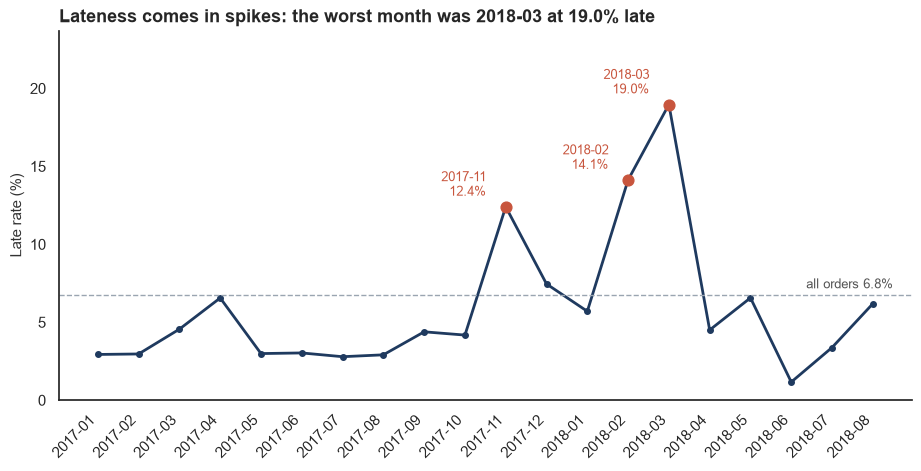

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(monthly))
ax.plot(x, monthly.late_rate * 100, color=NAVY, linewidth=2, marker="o", markersize=4)
ax.axhline(overall * 100, color=GREY, linestyle="--", linewidth=1)
ax.text(len(x) - 0.5, overall * 100 + 0.4, f"all orders {overall:.1%}", color="#555555", ha="right", fontsize=9)
for m in monthly.late_rate.nlargest(3).index:
    i = list(monthly.index).index(m)
    ax.scatter(i, monthly.late_rate[m] * 100, color=TERRA, s=60, zorder=3)
    ax.annotate(f"{m}\n{monthly.late_rate[m]:.1%}", (i, monthly.late_rate[m] * 100),
                textcoords="offset points", xytext=(-14, 8), ha="right", color=TERRA, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(monthly.index, rotation=45, ha="right")
ax.set_ylabel("Late rate (%)")
ax.set_ylim(0, monthly.late_rate.max() * 100 * 1.25)
ax.set_title(f"Lateness comes in spikes: the worst month was {peak_month} at {monthly.late_rate.max():.1%} late")
save(fig, "chart_late_by_month.png")
plt.show()

## 7. Repeat buying: do customers whose first order was late come back less?

I take each customer's first delivered order (by purchase time) and check whether they placed a second delivered order later.
Repeat buying is rare on Olist, so the numbers are small and I should not read too much into them.

In [16]:
# order each customer's orders by time and number them
d = df.sort_values("purchased_at")
d["order_no"] = d.groupby("customer_unique_id").cumcount() + 1
n_orders = d.groupby("customer_unique_id").order_id.size()

first = d[d.order_no == 1].set_index("customer_unique_id")
first["came_back"] = n_orders.reindex(first.index) >= 2
print(f"Customers: {len(first):,}")
print(f"Customers with a 2nd order: {first.came_back.sum():,} ({first.came_back.mean():.2%})")

repeat = first.groupby("is_late").agg(customers=("came_back", "size"), came_back=("came_back", "sum"),
                                      repeat_rate=("came_back", "mean"))
repeat.index = repeat.index.map({False: "First order on time", True: "First order late"})
print(repeat.style.format({"customers": "{:,}", "came_back": "{:,}", "repeat_rate": "{:.2%}"}).to_string())

rep_table = pd.crosstab(first.is_late, first.came_back)
chi2_r, p_r, dof_r, _ = stats.chi2_contingency(rep_table)
v_r = np.sqrt(chi2_r / (rep_table.values.sum() * (min(rep_table.shape) - 1)))
print(f"\nChi-square = {chi2_r:.2f}, dof = {dof_r}, p-value = {p_r:.3g}, Cramer's V = {v_r:.3f}")

Customers: 93,350
Customers with a 2nd order: 2,801 (3.00%)
 customers came_back repeat_rate
is_late   
First order on time 86,997 2,643 3.04%
First order late 6,353 158 2.49%


Chi-square = 5.99, dof = 1, p-value = 0.0144, Cramer's V = 0.008


Only 3% of customers ever come back for a second delivered order. Customers whose first order was late came back a little less,
and the p-value is under 0.05, but Cramer's V is close to zero, so the effect is tiny.
Also, customers whose first order was near the end of the data had less time to come back. I treat this result as a hint, not a finding to build on.

## 8. Promise padding: what if the promise were shorter?

The promise is on average much longer than the actual delivery time. A long promise can lose sales at checkout,
so I test a simple what-if: **if every promise were k days shorter, how many orders would be late?**

An order would be late under the new promise if it arrived less than k days early (`days_early < k`).

**Important limit:** this is a simple simulation. It assumes delivery times stay exactly the same. It does not count
any extra sales a shorter promise might bring, or any change in how carriers and sellers behave.

In [17]:
rows = []
for k in range(0, 15):
    rows.append({"k_days_shorter": k,
                 "avg_days_promised": df.promised_days.mean() - k,
                 "late_rate": (df.days_early < k).mean()})
whatif = pd.DataFrame(rows).set_index("k_days_shorter")
whatif["extra_late_pts"] = (whatif.late_rate - whatif.late_rate.iloc[0]) * 100
whatif.style.format({"avg_days_promised": "{:.1f}", "late_rate": "{:.1%}", "extra_late_pts": "{:+.1f}"})

,avg_days_promised,late_rate,extra_late_pts
k_days_shorter,,,
0,24.4,6.8%,+0.0
1,23.4,8.1%,+1.3
2,22.4,9.6%,+2.9
3,21.4,11.2%,+4.5
4,20.4,13.0%,+6.3
5,19.4,15.0%,+8.2
6,18.4,17.3%,+10.5
7,17.4,21.1%,+14.3
8,16.4,26.1%,+19.3


Suggested k = 2: average promise 24.4 -> 22.4 days, late rate 6.8% -> 9.6%


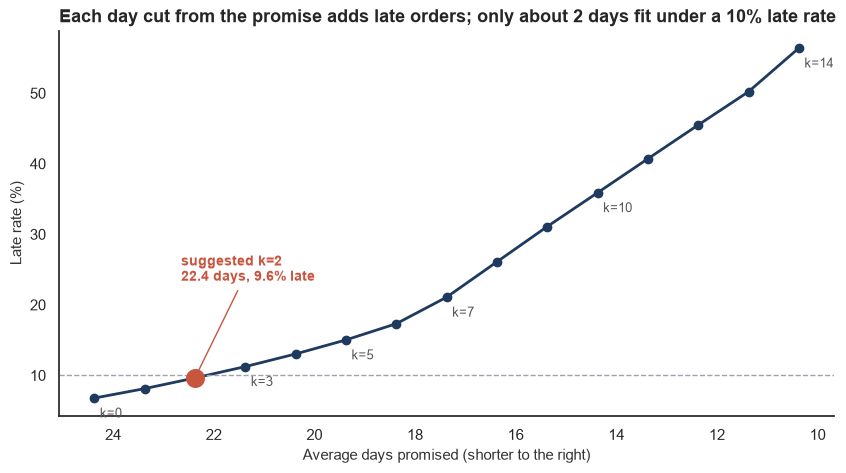

In [18]:
# pick k: the biggest cut that keeps the late rate under 10%
K_LIMIT = 0.10
k_pick = int(whatif[whatif.late_rate < K_LIMIT].index.max())
pick = whatif.loc[k_pick]
print(f"Suggested k = {k_pick}: average promise {whatif.avg_days_promised.iloc[0]:.1f} -> {pick.avg_days_promised:.1f} days, "
      f"late rate {whatif.late_rate.iloc[0]:.1%} -> {pick.late_rate:.1%}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(whatif.avg_days_promised, whatif.late_rate * 100, color=NAVY, linewidth=2, marker="o")
for k in [0, 3, 5, 7, 10, 14]:
    r = whatif.loc[k]
    ax.annotate(f"k={k}", (r.avg_days_promised, r.late_rate * 100), textcoords="offset points",
                xytext=(4, -14), fontsize=9, color="#555555")
ax.scatter(pick.avg_days_promised, pick.late_rate * 100, s=160, color=TERRA, zorder=3)
ax.annotate(f"suggested k={k_pick}\n{pick.avg_days_promised:.1f} days, {pick.late_rate:.1%} late",
            (pick.avg_days_promised, pick.late_rate * 100), textcoords="offset points",
            xytext=(-10, 70), color=TERRA, fontweight="bold",
            arrowprops=dict(arrowstyle="-", color=TERRA))
ax.axhline(K_LIMIT * 100, color=GREY, linestyle="--", linewidth=1)
ax.invert_xaxis()   # shorter promise to the right
ax.set_xlabel("Average days promised (shorter to the right)")
ax.set_ylabel("Late rate (%)")
ax.set_title(f"Each day cut from the promise adds late orders; only about {k_pick} days fit under a 10% late rate")
save(fig, "chart_promise_tradeoff.png")
plt.show()

This was not what I expected. Even though the median order is 12 days early, cutting every promise by the same amount gets expensive quickly:
each day adds about 1.3 to 2 points of late orders at first, and more after a week. The reason is the spread. One in ten orders arrives only 2 days
early or less, so a flat cut pushes those orders into "late". I picked k as the biggest cut that keeps the late rate under 10%, which is only 2 days.
A real business would set that limit based on what a late order costs compared with a lost sale, which I cannot see in this data.

### A rough what-if: a promise per customer state

Cutting every promise by the same k days is crude, because some states are slow and some are fast.
A smarter rule would set the promise for each customer state at a high percentile of past delivery days.

To keep it fair I use a time split: **learn the rule from 2017 orders and test it on 2018 orders.** This is still a rough what-if,
with the same limit as above (delivery times are assumed not to change).

In [19]:
train = df[df.purchased_at.dt.year == 2017]
test = df[df.purchased_at.dt.year == 2018].copy()
print(f"Learn on 2017: {len(train):,} orders | test on 2018: {len(test):,} orders")

results = [{"rule": "Current promise",
            "avg_days_promised": test.promised_days.mean(),
            "late_rate": test.is_late.mean()}]
for q in [0.90, 0.95]:
    # the promise for each state is the q-th percentile of 2017 delivery days, rounded up
    rule = np.ceil(train.groupby("customer_state").delivery_days.quantile(q))
    fallback = np.ceil(train.delivery_days.quantile(q))   # for any state not seen in 2017
    promise = test.customer_state.map(rule).fillna(fallback)
    results.append({"rule": f"State P{int(q*100)} of 2017 delivery days",
                    "avg_days_promised": promise.mean(),
                    "late_rate": (test.delivery_days > promise).mean()})
# for a fair comparison: the flat cut on the same 2018 orders
for k in [2, 3]:
    results.append({"rule": f"Current promise minus {k} days",
                    "avg_days_promised": test.promised_days.mean() - k,
                    "late_rate": (test.days_early < k).mean()})
state_rule = pd.DataFrame(results).set_index("rule")
state_rule.style.format({"avg_days_promised": "{:.1f}", "late_rate": "{:.1%}"})

Learn on 2017: 43,426 orders | test on 2018: 52,777 orders


,avg_days_promised,late_rate
rule,,
Current promise,23.4,7.7%
State P90 of 2017 delivery days,20.9,10.2%
State P95 of 2017 delivery days,26.1,5.4%
Current promise minus 2 days,21.4,11.3%
Current promise minus 3 days,20.4,13.3%


Delivery in 2018 was not the same as in 2017, so the rule learned from 2017 does not hit exactly 90% or 95% on time in 2018.
That is the point of testing it on a later year.

What the table shows: the P90 state rule gives a shorter average promise than the current one with a late rate of about 10%,
and it does a bit better than a flat cut of the same size (compare it with the "minus 2" and "minus 3" rows).
The P95 rule is the other way round: fewer late orders but a longer promise. So the current promise is not wildly padded for what it achieves;
most of the extra days are there to cover the slow tail of deliveries. A per-state (or better, per-route) promise is a cleaner way to trade
days against lateness than a flat cut. It is a rough idea to show the direction, not a model ready to use.

## 9. Findings and recommendations


- **The promise is missed on 6.77% of delivered orders (6,534 of 96,470), but most orders are very early.** The median order arrives 12 days before the promised date. On average Olist promises 24.4 days and delivers in 12.5.
- **A late order costs a lot in reviews.** Late orders average 2.27 stars against 4.29 for on-time orders, and 62.4% of late reviews are 1-2 stars against 9.3% (6.7 times as many). The link is strong: chi-square = 15,064 (p < 0.001), Cramer's V = 0.40; Mann-Whitney U = 103,305,546 (p < 0.001), rank-biserial r = -0.64. Arriving more than a week early adds almost nothing (4.30 for 7-13 days early, 4.32 for 14+).
- **Lateness comes from long routes, a few states, sellers who ship late, and peak months.** The late rate rises from 4.5% under 100 km to 12.1% over 2,000 km. MA (17.4%), CE (13.8%), BA (12.2%) and RJ (12.1%) are the worst large states. When the seller ships after its limit, 20.8% of orders are late against 5.4% otherwise. Lateness spiked in 2017-11 (12.4%), 2018-02 (14.1%) and 2018-03 (19.0%).
- **The effect on repeat buying is tiny.** Only 3.00% of customers place a second order. It is 2.53% after a late first order and 3.03% after an on-time one (chi-square = 4.95, p = 0.026, Cramer's V = 0.007).
- **A flat cut to the promise gets expensive fast.** Cutting every promise by 2 days (24.4 to 22.4 days) raises the late rate from 6.8% to 9.6%. A 7-day cut would mean 21.1% late. In a rough 2018 test, a per-state promise set at the 90th percentile of 2017 delivery days averaged 20.9 days with 10.2% late, a little better than a flat 3-day cut (20.4 days, 13.3% late).
- **Recommendations:** (1) Fix lateness at the source before shortening anything: hold sellers to their ship-by limit and watch the north-east routes and peak months (November, February-March). (2) Do not cut every promise by the same amount. If Olist wants shorter promises, set them per state or per route from past delivery times, and test the change on a small share of orders first. (3) Since being 7+ days early does not lift reviews, a shorter promise on fast, reliable routes (same state, under 500 km) is the safest place to start.

**Limits.** This is association, not cause. The data covers one marketplace in 2016-2018. Reviews come only from people who chose to leave one.
The what-if assumes delivery times would stay the same if the promise changed.